# Global Food Delivery Market 2026: Where Satisfaction and Margin Are Won and Lost

**Dataset:** 8,000 orders across 12 metro cities, 7 cuisines, 3 channels ([Kaggle](https://www.kaggle.com/datasets/luthfimuthathohirin/global-food-delivery-restaurant-market-2026)).

**Two lenses**
- **Platform:** where should a delivery platform spend to protect satisfaction (and so retention)?
- **Restaurant operator:** which orders make money for the restaurant, and which channel mix maximises it?

## Hypotheses tested

| # | Hypothesis | Verdict |
|---|---|---|
| H0 | Market (city) and cuisine drive satisfaction and margin | **Rejected** |
| H1 | Churn risk is a fulfilment-time problem; distance and peak hours act only through time, storms add independent risk | **Supported** |
| H2 | Discounts buy satisfaction | **Rejected** (no measurable effect, 11% of GMV) |
| H3 | Delivery-app orders structurally compress restaurant margin; pickup recovers most of it | **Supported** |

## Working assumptions
1. `customer_rating` ≤ 2.5 (tier `Dissatisfied-ChurRisk-1to2Star`, which despite its name includes 2.5) is the churn-risk proxy. There is no customer ID, so real retention can't be observed.
2. `estimated_restaurant_net_margin_usd` is taken as given. It is a near-deterministic function of order value and channel (R² = 1.000, shown below), so it is a modelled margin, not an accounting one.
3. `customer_satisfaction_tier` and `primary_satisfaction_driver` are labels derived from the rating and are **not** used as predictors (leakage).
4. `cot_market_dynamics_rationale` (LLM-generated text in Indonesian) and `confidence_score` are dropped.
5. The dataset is synthetic/enriched. Findings describe the mechanics of this dataset; external validity needs real order logs.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
import warnings; warnings.filterwarnings('ignore')

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'font.size': 10, 'text.parse_math': False})
INK, ACCENT, MUTED, BAD = '#1f2937', '#2563eb', '#9ca3af', '#dc2626'

df = pd.read_csv('../data/global_food_delivery_enriched_market_2026.csv')
df = df.drop(columns=['cot_market_dynamics_rationale', 'confidence_score'])
df['churn'] = (df.customer_satisfaction_tier == 'Dissatisfied-ChurRisk-1to2Star').astype(int)
df['margin_pct'] = df.estimated_restaurant_net_margin_usd / df.order_value_usd
d = df[df.order_channel == 'Online Delivery App'].copy()   # delivery-only subset
d['peak'] = d.is_peak_hour.astype(int)
d['storm'] = (d.weather_condition == 'Heavy Rain / Storm').astype(int)
d['rain'] = (d.weather_condition == 'Rainy').astype(int)
print(df.shape, '| delivery orders:', len(d), '| churn-risk orders:', df.churn.sum())

(8000, 26) | delivery orders: 5255 | churn-risk orders: 174


## 1. Data audit

In [2]:
print('Nulls:', int(df.isnull().sum().sum()), '| duplicate IDs:', int(df.order_id.duplicated().sum()))
print('Zero-discount share:', round((df.discount_percentage == 0).mean(), 3))
print('\nRating distribution:'); print(df.customer_rating.value_counts().sort_index().to_string())
df[['order_value_usd','discount_percentage','delivery_distance_km','total_fulfillment_time_min',
    'delivery_fee_usd','customer_rating','estimated_restaurant_net_margin_usd']].describe().round(2)

Nulls: 0 | duplicate IDs: 0
Zero-discount share: 0.416

Rating distribution:
customer_rating
1.0       1
1.5       3
2.0      40
2.5     130
3.0     358
3.5    1048
4.0    1932
4.5    2139
5.0    2349


,order_value_usd,discount_percentage,delivery_distance_km,total_fulfillment_time_min,delivery_fee_usd,customer_rating,estimated_restaurant_net_margin_usd
count,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00
mean,30.22,11.91,3.05,29.31,2.96,4.28,10.79
std,26.37,12.12,3.94,16.21,2.67,0.65,10.67
min,3.50,0.00,0.00,5.00,0.00,1.00,-0.21
25%,12.92,0.00,0.00,18.00,0.00,4.00,3.73
50%,21.70,9.54,1.60,26.00,2.97,4.50,7.44
75%,37.89,23.02,4.50,36.70,4.54,5.00,13.91
max,145.00,35.02,22.00,111.00,9.50,5.00,67.85


**Is margin observed or modelled?** A linear fit on order value and channel reproduces it almost exactly, so it is a formula. Discounts carry ~zero weight, meaning in this dataset discounts are platform-funded, not restaurant-funded.

In [3]:
fit = smf.ols('estimated_restaurant_net_margin_usd ~ order_value_usd * C(order_channel) + discount_applied_usd + delivery_fee_usd', df).fit()
print(f'R² = {fit.rsquared:.4f}')
fit.params.round(4)

R² = 1.0000


Intercept                                                 -0.2999
C(order_channel)[T.Online Delivery App]                   -1.2002
C(order_channel)[T.Takeaway / Pickup]                     -0.8998
order_value_usd                                            0.4700
order_value_usd:C(order_channel)[T.Online Delivery App]   -0.1000
order_value_usd:C(order_channel)[T.Takeaway / Pickup]     -0.0500
discount_applied_usd                                      -0.0000
delivery_fee_usd                                          -0.0000
dtype: float64

## 2. H0: Do city and cuisine matter? (No)
Before chasing market-level stories, test whether there is any market-level signal at all.

In [4]:
for col in ['metro_city', 'cuisine_category', 'weather_condition']:
    chi2, p, *_ = stats.chi2_contingency(pd.crosstab(df[col], df.churn))
    print(f'{col:20s} churn chi² = {chi2:6.1f}  p = {p:.3g}')
city = df.groupby('metro_city').agg(orders=('order_id','count'), rating=('customer_rating','mean'),
        churn_pct=('churn', lambda x: x.mean()*100), margin=('estimated_restaurant_net_margin_usd','mean')).round(2)
print('\nMargin range across cities: $%.2f – $%.2f' % (city.margin.min(), city.margin.max()))
city.sort_values('churn_pct', ascending=False)

metro_city           churn chi² =    8.6  p = 0.661
cuisine_category     churn chi² =    5.4  p = 0.497
weather_condition    churn chi² =   81.0  p = 1.86e-17

Margin range across cities: $10.03 – $11.27


,orders,rating,churn_pct,margin
metro_city,,,,
Sao Paulo,558,4.25,3.05,10.52
Singapore,676,4.28,2.81,10.57
Jakarta,824,4.30,2.55,10.48
Seoul,502,4.26,2.39,10.87
London,807,4.26,2.23,11.27
New York,1010,4.26,2.18,10.59
Toronto,464,4.30,2.16,11.14
Tokyo,914,4.33,2.08,10.99
Mumbai,493,4.30,1.83,11.14


In [5]:
m_naive = smf.logit('churn ~ C(metro_city) + C(cuisine_category) + discount_percentage', d).fit(disp=0)
m_ops   = smf.logit('churn ~ total_fulfillment_time_min + delivery_distance_km + delivery_fee_ratio + discount_percentage'
                    ' + order_value_usd + peak + storm + rain + C(metro_city) + C(cuisine_category)', d).fit(disp=0)
print(f'Pseudo-R²  city + cuisine + discount : {m_naive.prsquared:.3f}')
print(f'Pseudo-R²  + operational variables   : {m_ops.prsquared:.3f}')

Pseudo-R²  city + cuisine + discount : 0.009
Pseudo-R²  + operational variables   : 0.360


**Read:** city and cuisine explain under 1% of churn variance. Margin differs by about $1.20 across cities on a ~$30 basket. Any "expand in London, pull out of Berlin" recommendation from this data would be fitting noise. The variance is operational.

## 3. H1: Churn risk is a fulfilment-time problem

,orders,churn_pct,rating
time_band,,,
≤25,1280,0.39,4.35
25–35,1760,0.57,4.37
35–45,1127,0.62,4.36
45–60,667,3.60,4.05
>60,421,28.27,3.19


,orders,churn_pct,rating
dist_band,,,
≤2,1613,0.50,4.35
2–4,1402,0.64,4.38
4–7,1150,1.65,4.24
7–10,571,6.13,4.08
>10,519,18.11,3.59


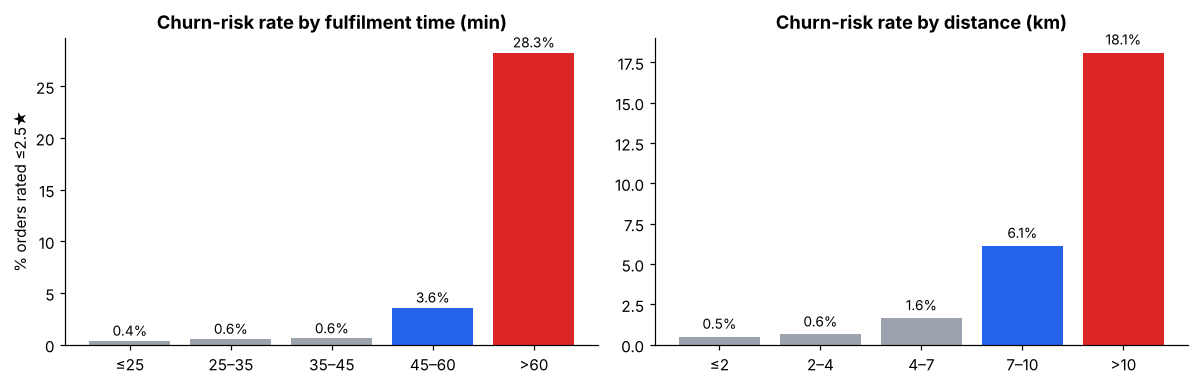

In [6]:
d['time_band'] = pd.cut(d.total_fulfillment_time_min, [0,25,35,45,60,200], labels=['≤25','25–35','35–45','45–60','>60'])
d['dist_band'] = pd.cut(d.delivery_distance_km, [-0.1,2,4,7,10,25], labels=['≤2','2–4','4–7','7–10','>10'])
tb = d.groupby('time_band').agg(orders=('order_id','count'), churn_pct=('churn', lambda x: x.mean()*100), rating=('customer_rating','mean')).round(2)
db = d.groupby('dist_band').agg(orders=('order_id','count'), churn_pct=('churn', lambda x: x.mean()*100), rating=('customer_rating','mean')).round(2)
display(tb); display(db)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(tb.index.astype(str), tb.churn_pct, color=[MUTED]*3 + [ACCENT, BAD])
ax[0].set_title('Churn-risk rate by fulfilment time (min)'); ax[0].set_ylabel('% orders rated ≤2.5★')
ax[1].bar(db.index.astype(str), db.churn_pct, color=[MUTED]*3 + [ACCENT, BAD])
ax[1].set_title('Churn-risk rate by distance (km)')
for a, t in zip(ax, [tb, db]):
    for i, v in enumerate(t.churn_pct): a.text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=9)
plt.tight_layout(); plt.savefig('../figures/churn-by-time-distance.png', bbox_inches='tight'); plt.show()

Time and distance are correlated (ρ ≈ 0.75), so the bivariate view can't tell which one does the damage. The multivariate logit separates them:

In [7]:
keep = ['total_fulfillment_time_min','delivery_distance_km','delivery_fee_ratio','discount_percentage','order_value_usd','peak','storm','rain']
tab = pd.DataFrame({'coef': m_ops.params[keep], 'odds_ratio': np.exp(m_ops.params[keep]), 'p': m_ops.pvalues[keep]}).round(4)
tab

,coef,odds_ratio,p
total_fulfillment_time_min,0.0871,1.0910,0.0000
delivery_distance_km,-0.0144,0.9857,0.7117
delivery_fee_ratio,0.2236,1.2506,0.4095
discount_percentage,0.0005,1.0005,0.9508
order_value_usd,-0.0005,0.9995,0.9231
peak,-0.3352,0.7152,0.2605
storm,0.8658,2.3769,0.0027
rain,0.0481,1.0492,0.8405


**Read:**
- Each extra minute of fulfilment raises churn odds by **~9%** (OR 1.09, p < 0.001). Ten extra minutes is roughly 2.4× the odds.
- **Distance and peak hour lose significance** once time is controlled. They hurt only because they make orders slower. The lever is the clock, not the map.
- **Storms add independent risk** (OR ≈ 2.4, p ≈ 0.003) beyond the delay they cause. Customers judge storm orders more harshly at the same wait.
- Discount, basket size and fee ratio have no independent effect.

In [8]:
risk = (d.total_fulfillment_time_min > 45) | (d.delivery_distance_km > 7)
print(f'Risk zone (>45 min OR >7 km): {risk.mean():.1%} of delivery orders')
print(f'  holds {d[risk].churn.sum() / df.churn.sum():.1%} of ALL churn-risk orders in the dataset')
print(f'  churn rate inside {d[risk].churn.mean():.1%} vs outside {d[~risk].churn.mean():.2%}')
print(f'\nChannel share of all churn-risk orders: delivery {d.churn.sum()/df.churn.sum():.1%}')
print(d.groupby('weather_condition').agg(fulfil_min=('total_fulfillment_time_min','mean'), speed_kmh=('delivery_speed_km_per_hr','mean'), churn_pct=('churn', lambda x: x.mean()*100)).round(2))

Risk zone (>45 min OR >7 km): 28.0% of delivery orders
  holds 84.5% of ALL churn-risk orders in the dataset
  churn rate inside 10.0% vs outside 0.48%

Channel share of all churn-risk orders: delivery 94.8%
                    fulfil_min  speed_kmh  churn_pct
weather_condition                                   
Clear                    34.97      16.63       2.20
Cloudy / Fog             34.46      16.75       2.14
Heavy Rain / Storm       43.30      11.46      10.67
Rainy                    37.66      14.08       3.36


**This is the core finding.** 95% of churn risk sits in the delivery channel, and 85% of it sits in the 28% of delivery orders that run past 45 minutes or 7 km. Churn risk is concentrated in that band, which makes it targetable.

## 4. H2: Do discounts buy satisfaction? (No)

In [9]:
df['disc_band'] = pd.cut(df.discount_percentage, [-0.01, 0, 10, 20, 40], labels=['0%', '0–10%', '10–20%', '20%+'])
disc = df.groupby('disc_band').agg(orders=('order_id','count'), rating=('customer_rating','mean'),
        churn_pct=('churn', lambda x: x.mean()*100), aov=('order_value_usd','mean')).round(3)
display(disc)
r, p = stats.spearmanr(df.discount_percentage, df.customer_rating)
print(f'Spearman(discount %, rating) = {r:.4f}, p = {p:.2f}')
print(f'Discount spend: ${df.discount_applied_usd.sum():,.0f} on ${df.order_value_usd.sum():,.0f} GMV = {df.discount_applied_usd.sum()/df.order_value_usd.sum():.1%}')

,orders,rating,churn_pct,aov
disc_band,,,,
0%,3332,4.280,2.131,30.212
0–10%,722,4.242,2.770,41.886
10–20%,1495,4.294,2.609,30.457
20%+,2451,4.287,1.795,26.660


Spearman(discount %, rating) = 0.0032, p = 0.77
Discount spend: $26,629 on $241,783 GMV = 11.0%


**Read:** ratings are flat across discount bands (4.24–4.29), the correlation is zero, and discounting is insignificant in the logit controlling for everything else. The platform spends **11% of GMV** on discounts with no satisfaction return.

**Limit of this claim:** without customer IDs or timestamps we can't test whether discounts drive *acquisition or order frequency*. The defensible conclusion is narrower: discounts do not improve the experience of the order they are applied to, so they can't be justified on satisfaction grounds. Any retention case for them has to be proven with a holdout test.

## 5. H3: Restaurant economics by channel

,orders,aov,margin_usd,margin_pct,rating,churn_pct
order_channel,,,,,,
Dine-In POS,1577,30.294,13.938,0.452,4.393,0.254
Online Delivery App,5255,29.921,9.571,0.277,4.228,3.140
Takeaway / Pickup,1168,31.485,12.024,0.348,4.369,0.428


order_channel,Dine-In POS,Online Delivery App,Takeaway / Pickup
restaurant_price_tier,,,
$ Budget,0.442,0.231,0.310
$$ Moderate,0.457,0.303,0.368
$$$ Premium / Fine Dining,0.465,0.344,0.400


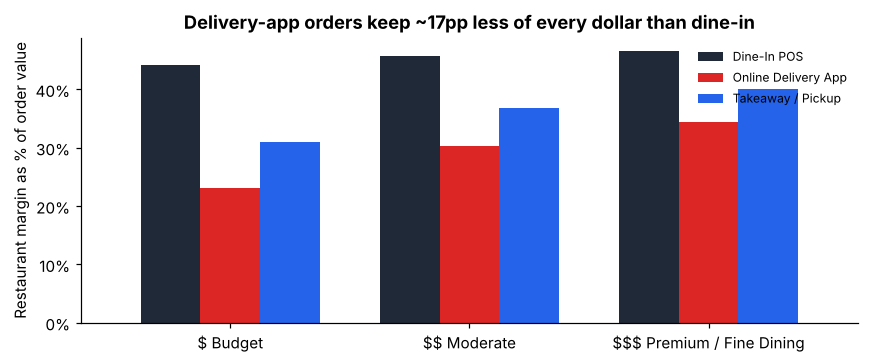

In [10]:
ch = df.groupby('order_channel').agg(orders=('order_id','count'), aov=('order_value_usd','mean'),
        margin_usd=('estimated_restaurant_net_margin_usd','mean'), margin_pct=('margin_pct','mean'),
        rating=('customer_rating','mean'), churn_pct=('churn', lambda x: x.mean()*100)).round(3)
display(ch)
tier = df.pivot_table('margin_pct', 'restaurant_price_tier', 'order_channel', 'mean').round(3)
display(tier)

fig, ax = plt.subplots(figsize=(8, 3.4))
tier.plot.bar(ax=ax, color=[INK, BAD, ACCENT], rot=0, width=0.75)
ax.set_ylabel('Restaurant margin as % of order value'); ax.set_xlabel('')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_title('Delivery-app orders keep ~17pp less of every dollar than dine-in'); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig('../figures/margin-by-channel-tier.png', bbox_inches='tight'); plt.show()

**Read:** for the same basket, a restaurant keeps **45%** on dine-in, **35%** on pickup and **28%** on the delivery app. Budget restaurants on the app keep just 23%. Pickup closes about 40% of the delivery gap, and it is the channel restaurants can steer with their own incentives.

In [11]:
neg = df[df.estimated_restaurant_net_margin_usd < 0]
print(f'Loss-making orders: {len(neg)} ({len(neg)/len(df):.1%}), all on channel: {list(neg.order_channel.unique())}')
print(f'Order value range of loss-makers: ${neg.order_value_usd.min():.2f}–${neg.order_value_usd.max():.2f}; worst loss ${neg.estimated_restaurant_net_margin_usd.min():.2f}')
d['fee_band'] = pd.cut(d.delivery_fee_ratio, [-0.01, .1, .25, .5, 1, 3], labels=['<10%','10–25%','25–50%','50–100%','>100%'])
d.groupby('fee_band').agg(orders=('order_id','count'), aov=('order_value_usd','mean'), margin=('estimated_restaurant_net_margin_usd','mean'),
        churn_pct=('churn', lambda x: x.mean()*100), loss_pct=('estimated_restaurant_net_margin_usd', lambda x: (x<0).mean()*100)).round(2)

Loss-making orders: 91 (1.1%), all on channel: ['Online Delivery App']
Order value range of loss-makers: $3.50–$4.03; worst loss $-0.21


,orders,aov,margin,churn_pct,loss_pct
fee_band,,,,,
<10%,1235,63.38,21.95,0.81,0.00
10–25%,2026,26.69,8.37,1.92,0.00
25–50%,1268,15.08,4.08,4.97,0.00
50–100%,559,8.77,1.75,5.19,5.72
>100%,167,5.21,0.43,14.37,35.33


**Read:** loss-making orders exist, but they are a tiny floor problem: 91 orders, all delivery, all under $4.05. A **$5 minimum basket** removes every one. A minimum basket isn't a big margin lever, though. The bigger issue is that small baskets (fee > 25% of value) carry **5–14% churn** against <2% for larger ones. That looks like fee-shock bias in ratings, but fee ratio was insignificant once time was controlled, so treat it as a secondary effect.

## 6. What the levers are worth (model-implied)
Two levers, sized against this dataset. These are counterfactual estimates from the fitted logit and the channel margin gap, not observed outcomes.

In [12]:
# Lever 1: 45-minute fulfilment cap on delivery
cf = d.copy(); cf['total_fulfillment_time_min'] = cf.total_fulfillment_time_min.clip(upper=45)
base, capped = m_ops.predict(d).sum(), m_ops.predict(cf).sum()
print(f'Lever 1: cap delivery fulfilment at 45 min')
print(f'  orders affected: {(d.total_fulfillment_time_min > 45).sum()} ({(d.total_fulfillment_time_min > 45).mean():.1%} of delivery)')
print(f'  predicted churn-risk orders: {base:.0f} → {capped:.0f} ({1 - capped/base:.0%} reduction)')

# Lever 2: shift 10% of delivery orders to pickup (restaurant view)
gap = ch.loc['Takeaway / Pickup', 'margin_pct'] - ch.loc['Online Delivery App', 'margin_pct']
shift = 0.10 * len(d)
gain = shift * d.order_value_usd.mean() * gap
print(f'\nLever 2: shift 10% of app orders to pickup')
print(f'  margin gap {gap:.1%} of order value → ${gain:,.0f} extra restaurant margin on {shift:.0f} orders')
print(f'  = +{gain / df.estimated_restaurant_net_margin_usd.sum():.1%} total restaurant margin; break-even pickup incentive ≈ ${d.order_value_usd.mean()*gap:.2f}/order')

Lever 1: cap delivery fulfilment at 45 min
  orders affected: 1088 (20.7% of delivery)
  predicted churn-risk orders: 165 → 55 (67% reduction)

Lever 2: shift 10% of app orders to pickup
  margin gap 7.1% of order value → $1,116 extra restaurant margin on 526 orders
  = +1.3% total restaurant margin; break-even pickup incentive ≈ $2.12/order


## 7. Conclusions

**Platform.** Satisfaction risk in this market comes from delivery time. Pricing, location and cuisine barely register. Per minute, fulfilment time is the only operational variable that moves churn; distance and rush hour act through it. Two recommendations follow:
1. **Enforce a 45-minute promise.** Use dispatch radius and batching rules so no order quotes beyond 45 minutes. In storms, tighten it further, since customers are harsher at the same wait. The model implies roughly two thirds fewer churn-risk orders.
2. **Put discount budget on trial.** It costs 11% of GMV with no measurable satisfaction effect. Run a holdout before renewing it and fund the time SLA from it first.

**Restaurant operator.** The app costs about 17pp of margin versus dine-in, and 7pp versus pickup. A pickup incentive is self-funding up to about $2.10 per order. Set a $5 delivery minimum to clear the loss-making floor.

**What this analysis cannot claim:** effects on real retention, order frequency or acquisition (no customer IDs or timestamps), and real-world magnitudes (the dataset is synthetic and margin is formula-derived).